- **Гипотеза 1.** Нужно посмотреть на каких станциях брали больше и оставли меньше, это поможет выявить где можно добавить количество велосипедов.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq

- читаю файл bike_share/usage_frequency.csv

In [2]:
usage_frequency = pd.read_csv('../../../bike_share/usage_frequency.csv')
usage_frequency

,date,station_name,pickup_counts,dropoff_counts
0,2020-05-01,10th & E St NW,11,7.0
1,2020-05-01,10th & Florida Ave NW,8,8.0
2,2020-05-01,10th & G St NW,3,2.0
3,2020-05-01,10th & K St NW,12,15.0
4,2020-05-01,10th & Monroe St NE,5,6.0
...,...,...,...,...
873313,2024-08-31,Wisconsin Ave & Upton St NW,28,26.0
873314,2024-08-31,Woodglen Dr & Executive Blvd,4,1.0
873315,2024-08-31,Woodley Park Metro / Calvert St & Connecticut ...,34,34.0
873316,2024-08-31,Woodmont Ave & Strathmore St,10,7.0


- добавляю столбец change это разница между сколько взяли и сколько оставили

In [3]:
usage_frequency['change'] = usage_frequency['dropoff_counts'] - usage_frequency['pickup_counts']

- вывел что получилось

In [4]:
usage_frequency

,date,station_name,pickup_counts,dropoff_counts,change
0,2020-05-01,10th & E St NW,11,7.0,-4.0
1,2020-05-01,10th & Florida Ave NW,8,8.0,0.0
2,2020-05-01,10th & G St NW,3,2.0,-1.0
3,2020-05-01,10th & K St NW,12,15.0,3.0
4,2020-05-01,10th & Monroe St NE,5,6.0,1.0
...,...,...,...,...,...
873313,2024-08-31,Wisconsin Ave & Upton St NW,28,26.0,-2.0
873314,2024-08-31,Woodglen Dr & Executive Blvd,4,1.0,-3.0
873315,2024-08-31,Woodley Park Metro / Calvert St & Connecticut ...,34,34.0,0.0
873316,2024-08-31,Woodmont Ave & Strathmore St,10,7.0,-3.0


- меняю тип данных для столбца 'date'

In [5]:
usage_frequency['date'] = pd.to_datetime(usage_frequency['date'])

- считаю сколько дней отработала каждая станция и сразу записываю в словарь

In [6]:
station_work_day = usage_frequency.groupby('station_name')['date'].unique().apply(lambda x: len(x)).to_dict()
station_work_day

{' S Scott St & 13th St S': 113,
 '10th & E St NW': 1573,
 '10th & Florida Ave NW': 839,
 '10th & G St NW': 1574,
 '10th & H St NE': 1004,
 '10th & K St NW': 1583,
 '10th & Monroe St NE': 1560,
 '10th & Quincy St NE / Turkey Thicket Rec': 578,
 '10th & Rhode Island Ave NE': 1,
 '10th & U St NW': 1582,
 '10th St & Constitution Ave NW': 1554,
 '10th St & Florida Ave NW': 744,
 "10th St & L'Enfant Plaza SW": 1536,
 '10th St & Rhode Island Ave NE': 717,
 '10th St & Spring Rd NW': 494,
 '11th & C St SE': 1579,
 '11th & Clifton St NW': 740,
 '11th & F St NW': 1568,
 '11th & Girard St NW': 1584,
 '11th & H St NE': 573,
 '11th & Kenyon St NW': 1584,
 '11th & M St NW': 1584,
 '11th & O St NW': 1584,
 '11th & Park Rd NW': 1584,
 '11th & S St NW': 1581,
 '11th & V St NW': 703,
 '11th & V st NW': 357,
 '12th & Irving St NE': 1542,
 '12th & L St NW': 1583,
 '12th & Newton St NE': 1478,
 '12th & U St NW': 1577,
 '12th & Varnum St NE': 493,
 '12th St & New York Ave NW': 570,
 '12th St & Pennsylvania 

- добавляю столбец station_work_day в DataFrame usage_frequency

In [7]:
usage_frequency['station_work_day'] = usage_frequency['station_name'].map(station_work_day)

- вывожу результат

In [8]:
usage_frequency

,date,station_name,pickup_counts,dropoff_counts,change,station_work_day
0,2020-05-01,10th & E St NW,11,7.0,-4.0,1573
1,2020-05-01,10th & Florida Ave NW,8,8.0,0.0,839
2,2020-05-01,10th & G St NW,3,2.0,-1.0,1574
3,2020-05-01,10th & K St NW,12,15.0,3.0,1583
4,2020-05-01,10th & Monroe St NE,5,6.0,1.0,1560
...,...,...,...,...,...,...
873313,2024-08-31,Wisconsin Ave & Upton St NW,28,26.0,-2.0,279
873314,2024-08-31,Woodglen Dr & Executive Blvd,4,1.0,-3.0,1161
873315,2024-08-31,Woodley Park Metro / Calvert St & Connecticut ...,34,34.0,0.0,1583
873316,2024-08-31,Woodmont Ave & Strathmore St,10,7.0,-3.0,1534


- считаю сколько будет нехатать или будет переизбыток велосипедов на станции

In [9]:
result = usage_frequency.groupby('station_name')['change'].sum().reset_index()
result

,station_name,change
0,S Scott St & 13th St S,-10.0
1,10th & E St NW,4773.0
2,10th & Florida Ave NW,-157.0
3,10th & G St NW,8271.0
4,10th & H St NE,587.0
...,...,...
903,Woodglen Dr & Executive Blvd,-187.0
904,Woodley Park Metro / Calvert St & Connecticut ...,-8831.0
905,Woodmont Ave & Strathmore St,-1029.0
906,Woody Ward Rec Center,-35.0


- добавляю столбец station_work_day в DataFrame - result

In [10]:
result['station_work_day'] = result['station_name'].map(station_work_day)
result

,station_name,change,station_work_day
0,S Scott St & 13th St S,-10.0,113
1,10th & E St NW,4773.0,1573
2,10th & Florida Ave NW,-157.0,839
3,10th & G St NW,8271.0,1574
4,10th & H St NE,587.0,1004
...,...,...,...
903,Woodglen Dr & Executive Blvd,-187.0,1161
904,Woodley Park Metro / Calvert St & Connecticut ...,-8831.0,1583
905,Woodmont Ave & Strathmore St,-1029.0,1534
906,Woody Ward Rec Center,-35.0,147


- считаю сколько будет за один день недостаток или переизбыток велосипедов на станции

In [11]:
result["imbalance_ratio"] = result['change'] / result['station_work_day']
result

,station_name,change,station_work_day,imbalance_ratio
0,S Scott St & 13th St S,-10.0,113,-0.088496
1,10th & E St NW,4773.0,1573,3.034329
2,10th & Florida Ave NW,-157.0,839,-0.187128
3,10th & G St NW,8271.0,1574,5.254765
4,10th & H St NE,587.0,1004,0.584661
...,...,...,...,...
903,Woodglen Dr & Executive Blvd,-187.0,1161,-0.161068
904,Woodley Park Metro / Calvert St & Connecticut ...,-8831.0,1583,-5.578648
905,Woodmont Ave & Strathmore St,-1029.0,1534,-0.670795
906,Woody Ward Rec Center,-35.0,147,-0.238095


- добавляю столбцы surplus и deficit что потом посмотреть резкльтат уже по станциям

In [12]:
result["surplus"] = result["imbalance_ratio"].clip(lower=0)
result["deficit"] = (-result["imbalance_ratio"]).clip(lower=0)

- вывел топ-20 станций с избытком велосипедов

In [13]:
result.sort_values(by='surplus', ascending=False).head(20)

,station_name,change,station_work_day,imbalance_ratio,surplus,deficit
447,Georgetown Harbor / 30th St NW,16061.0,1575,10.197460,10.197460,0.0
809,Thomas Jefferson St NW & Water/K St NW,12391.0,1240,9.992742,9.992742,0.0
252,9th St & Pennsylvania Ave NW,5327.0,576,9.248264,9.248264,0.0
306,C & O Canal & Wisconsin Ave NW,13901.0,1581,8.792536,8.792536,0.0
553,Lynn St & 19th St North,7174.0,926,7.747300,7.747300,0.0
585,Metro Center / 12th & G St NW,11491.0,1574,7.300508,7.300508,0.0
175,34th & Water St NW,10925.0,1556,7.021208,7.021208,0.0
687,Potomac & M St NW,10762.0,1570,6.854777,6.854777,0.0
159,23rd & M St NW,9846.0,1584,6.215909,6.215909,0.0
567,Maine Ave & Water St SW,4023.0,756,5.321429,5.321429,0.0


- вывел топ-20 станций с дефицитом велосипедов

In [14]:
result.sort_values(by='deficit', ascending=False).head(20)

,station_name,change,station_work_day,imbalance_ratio,surplus,deficit
20,11th & Kenyon St NW,-21867.0,1584,-13.804924,0.0,13.804924
671,Park Rd & Holmead Pl NW,-21573.0,1582,-13.636536,0.0,13.636536
69,15th & Euclid St NW,-5899.0,464,-12.713362,0.0,12.713362
84,16th & Harvard St NW,-15513.0,1253,-12.380686,0.0,12.380686
50,14th & Irving St NW,-17214.0,1583,-10.874289,0.0,10.874289
54,14th & Otis Pl NW,-16404.0,1584,-10.356061,0.0,10.356061
326,Columbia & Ontario Rd NW,-15579.0,1583,-9.841440,0.0,9.841440
340,Columbia Rd & Georgia Ave NW,-14013.0,1583,-8.852179,0.0,8.852179
16,11th & Clifton St NW,-5306.0,740,-7.170270,0.0,7.170270
339,Columbia Rd & Belmont St NW,-10886.0,1584,-6.872475,0.0,6.872475


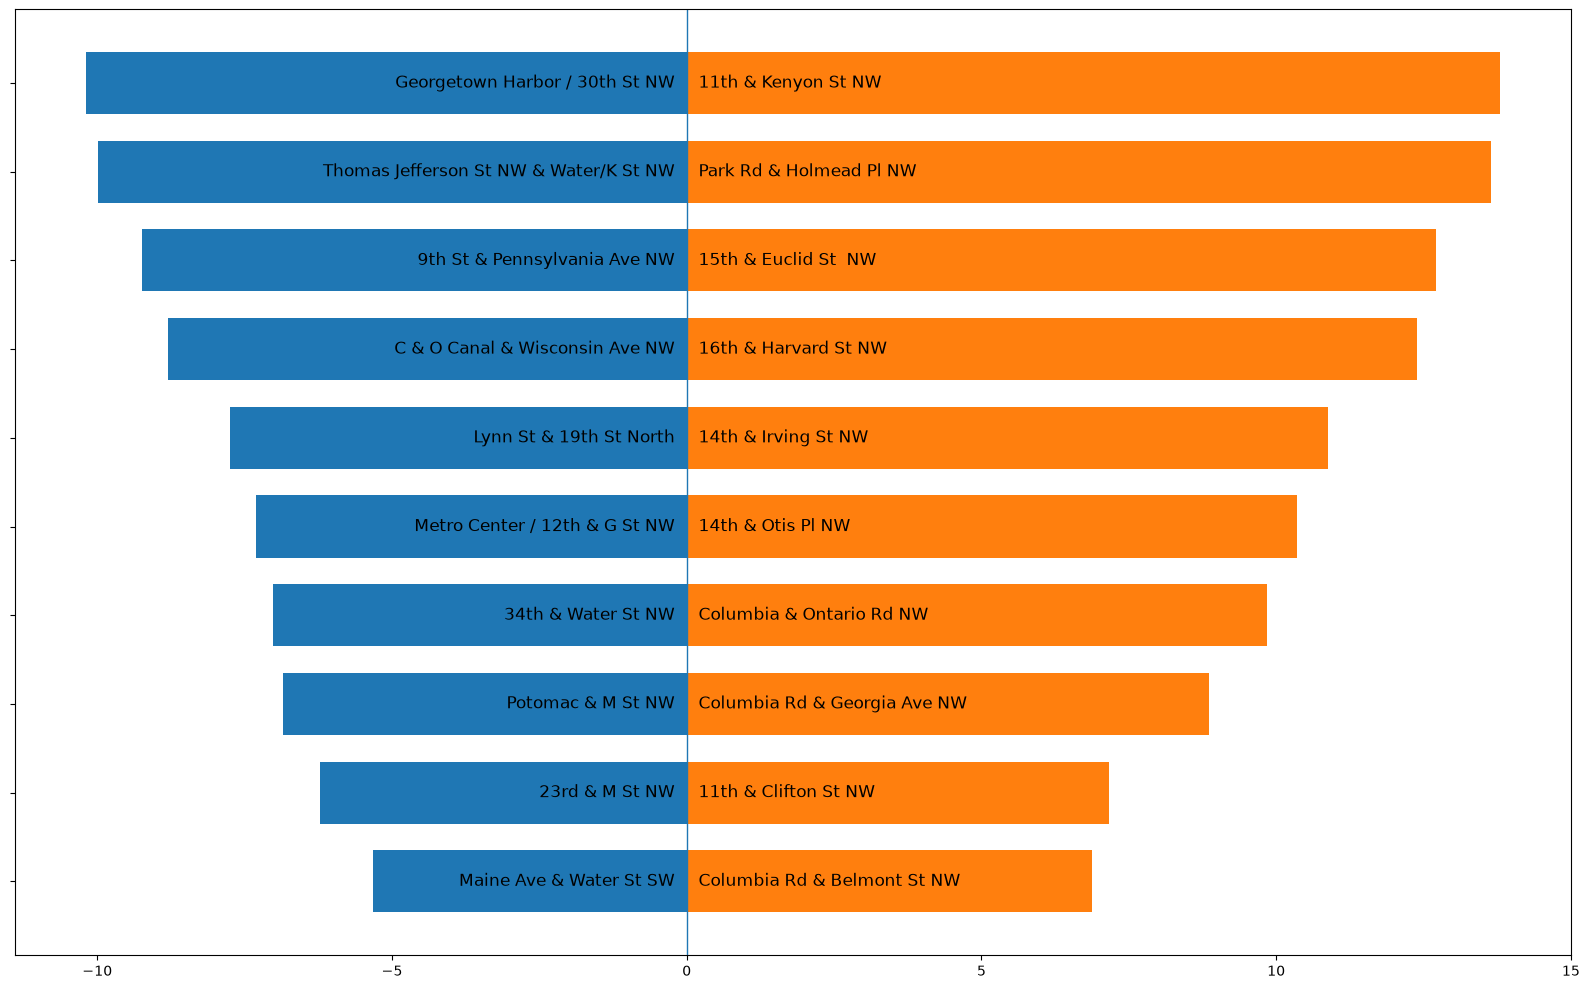

In [15]:
top1 = result.sort_values(by='surplus', ascending=False).head(10)
top2 = result.sort_values(by='deficit', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(16, 10))

y = np.arange(10)

# Левая группа
ax.barh(
    y,
    -top1["surplus"].values,
    height=0.7
)

# Правая группа
ax.barh(
    y,
    top2["deficit"].values,
    height=0.7
)

# Центральная линия
ax.axvline(0, linewidth=1)

# Убираем стандартные подписи Y
ax.set_yticks(y)
ax.set_yticklabels([])

# Названия слева
for i, station in enumerate(top1["station_name"]):
    ax.text(
        -0.2,
        i,
        station,
        ha="right",
        va="center",
        fontsize=12
    )

# Названия справа
for i, station in enumerate(top2["station_name"]):
    ax.text(
        0.2,
        i,
        station,
        ha="left",
        va="center",
        fontsize=12
    )

ax.invert_yaxis()

plt.tight_layout()
plt.show()

## Промежуточный вывод по гипотезе 1

- **Гипотеза 1.** Нужно посмотреть на каких станциях брали больше и оставли меньше, это поможет выявить где можно добавить количество велосипедов.


- Я узнал на каких станция есть переизбыток велосипедов и есть недостаток велосипедов вывел топ - 20
- Теперь я собираюсь более детально исследовать дефицит и профицит велосипедов разделив на группы:
    - типы велосипедов (docked_bike, classic_bike, electric_bike)
    - типы пользователей (member, casual)

## Выясняю какие типы байков находятся в избытке или недостатке:
- docked_bike
- classic_bike
- electric_bike

In [16]:
daily_rent_detail = pd.read_parquet('../../../data_after_preprocessing/daily_rent_detail.parquet')
daily_rent_detail

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_in_minutes
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,Anacostia Library,31804,11th & H St NE,31614,38.865784,-76.978401,38.899982,-76.991386,casual,1499.883301
1,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,10th & E St NW,31256,21st St & Constitution Ave NW,31261,38.895912,-77.026062,38.892460,-77.046570,member,24.483334
2,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,38.934265,-77.057976,38.916786,-77.028137,member,16.533333
3,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,38.934265,-77.057976,38.921074,-77.031883,casual,17.350000
4,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,38.932129,-77.023499,38.902760,-77.038628,casual,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,117C27DBDD138B72,electric_bike,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,NaN,0,NaN,0,38.889999,-77.000000,38.889999,-77.000000,member,0.255800
16086668,4774F4D630258482,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,NaN,0,NaN,0,38.900002,-77.000000,38.869999,-76.949997,member,16.411934
16086669,D75836E25E77B5EC,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,NaN,0,NaN,0,38.919998,-76.989998,38.919998,-77.000000,member,6.182117
16086670,3B888603D18116DC,electric_bike,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,NaN,0,NaN,0,38.919998,-77.019997,38.919998,-77.029999,member,10.186934


- убираю станции, которые равны 0 (данные были заменены, так как данные отсутствовали)

In [18]:
daily_rent_detail = daily_rent_detail[(daily_rent_detail['start_station_id'] != 0) & (daily_rent_detail['end_station_id'] != 0)]

- смотрю что получилось

In [19]:
daily_rent_detail

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_in_minutes
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,Anacostia Library,31804,11th & H St NE,31614,38.865784,-76.978401,38.899982,-76.991386,casual,1499.883301
1,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,10th & E St NW,31256,21st St & Constitution Ave NW,31261,38.895912,-77.026062,38.892460,-77.046570,member,24.483334
2,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,38.934265,-77.057976,38.916786,-77.028137,member,16.533333
3,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,38.934265,-77.057976,38.921074,-77.031883,casual,17.350000
4,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,38.932129,-77.023499,38.902760,-77.038628,casual,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16083915,0B1E598A0BB5267A,classic_bike,2024-08-22 18:12:12.444,2024-08-22 18:59:58.532,Braddock Rd Metro North,31047,Braddock Rd Metro North,31047,38.814575,-77.052811,38.814575,-77.052811,casual,47.768135
16084580,F5F912CEC7167D79,classic_bike,2024-08-23 11:58:30.749,2024-08-23 12:00:33.749,10th & H St NE,31672,10th & H St NE,31672,38.899982,-76.992722,38.899982,-76.992722,casual,2.050000
16085242,9E2EEBF255746B1E,electric_bike,2024-08-22 13:09:17.036,2024-08-22 13:35:13.814,Wisconsin Ave & Newark St NW,31302,Wisconsin Ave & Newark St NW,31302,38.934879,-77.072754,38.934879,-77.072754,member,25.946301
16085464,2CBC6A5EB1668ABB,electric_bike,2024-08-17 09:24:19.031,2024-08-17 09:41:27.044,14th & Belmont St NW,31119,Wisconsin Ave & Newark St NW,31302,38.920807,-77.031548,38.934879,-77.072754,casual,17.133551


- меняю тип данных для столбца started_at

In [20]:
daily_rent_detail['date'] = pd.to_datetime(daily_rent_detail['started_at'].dt.date)

- меняю название для DataFrame usage_frequency c station_name на start_station_name

In [21]:
usage_frequency = usage_frequency.rename(columns={'station_name': 'start_station_name'})

- вывожу результат

In [22]:
usage_frequency

,date,start_station_name,pickup_counts,dropoff_counts,change,station_work_day
0,2020-05-01,10th & E St NW,11,7.0,-4.0,1573
1,2020-05-01,10th & Florida Ave NW,8,8.0,0.0,839
2,2020-05-01,10th & G St NW,3,2.0,-1.0,1574
3,2020-05-01,10th & K St NW,12,15.0,3.0,1583
4,2020-05-01,10th & Monroe St NE,5,6.0,1.0,1560
...,...,...,...,...,...,...
873313,2024-08-31,Wisconsin Ave & Upton St NW,28,26.0,-2.0,279
873314,2024-08-31,Woodglen Dr & Executive Blvd,4,1.0,-3.0,1161
873315,2024-08-31,Woodley Park Metro / Calvert St & Connecticut ...,34,34.0,0.0,1583
873316,2024-08-31,Woodmont Ave & Strathmore St,10,7.0,-3.0,1534


- делаю слияние DataFrames - daily_rent_detail с usage_frequency

In [23]:
daily_rent_detail = daily_rent_detail.merge(usage_frequency, how='inner', on=['date', 'start_station_name'])

- вывожу результат

In [24]:
daily_rent_detail

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_in_minutes,date,pickup_counts,dropoff_counts,change,station_work_day
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,Anacostia Library,31804,11th & H St NE,31614,38.865784,-76.978401,38.899982,-76.991386,casual,1499.883301,2020-05-30,3,1.0,-2.0,1045
1,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,10th & E St NW,31256,21st St & Constitution Ave NW,31261,38.895912,-77.026062,38.892460,-77.046570,member,24.483334,2020-05-09,4,4.0,0.0,1573
2,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,38.934265,-77.057976,38.916786,-77.028137,member,16.533333,2020-05-24,17,10.0,-7.0,667
3,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,38.934265,-77.057976,38.921074,-77.031883,casual,17.350000,2020-05-27,13,11.0,-2.0,667
4,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,38.932129,-77.023499,38.902760,-77.038628,casual,24.450001,2020-05-31,12,11.0,-1.0,1579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13920681,0B1E598A0BB5267A,classic_bike,2024-08-22 18:12:12.444,2024-08-22 18:59:58.532,Braddock Rd Metro North,31047,Braddock Rd Metro North,31047,38.814575,-77.052811,38.814575,-77.052811,casual,47.768135,2024-08-22,9,6.0,-3.0,893
13920682,F5F912CEC7167D79,classic_bike,2024-08-23 11:58:30.749,2024-08-23 12:00:33.749,10th & H St NE,31672,10th & H St NE,31672,38.899982,-76.992722,38.899982,-76.992722,casual,2.050000,2024-08-23,40,31.0,-9.0,1004
13920683,9E2EEBF255746B1E,electric_bike,2024-08-22 13:09:17.036,2024-08-22 13:35:13.814,Wisconsin Ave & Newark St NW,31302,Wisconsin Ave & Newark St NW,31302,38.934879,-77.072754,38.934879,-77.072754,member,25.946301,2024-08-22,34,37.0,3.0,1583
13920684,2CBC6A5EB1668ABB,electric_bike,2024-08-17 09:24:19.031,2024-08-17 09:41:27.044,14th & Belmont St NW,31119,Wisconsin Ave & Newark St NW,31302,38.920807,-77.031548,38.934879,-77.072754,casual,17.133551,2024-08-17,90,83.0,-7.0,1582


- делаю группировку по столбцам rideable_type, start_station_id, start_station_name и считаю сумму по столбцу change

In [25]:
result_type_bike = daily_rent_detail.groupby(
    ['rideable_type','start_station_id', 'start_station_name']
)['change'].sum().reset_index()

- добавляю столбец station_work_day - то сколько дней работает станция

In [26]:
result_type_bike['station_work_day'] = result_type_bike['start_station_name'].map(station_work_day)

- вывожу результат 

In [27]:
result_type_bike

,rideable_type,start_station_id,start_station_name,change,station_work_day
0,classic_bike,30200,9th St & Pennsylvania Ave NW,121314.0,576
1,classic_bike,30201,9th & G St NW,35861.0,577
2,classic_bike,31000,Eads St & 15th St S,-3989.0,1499
3,classic_bike,31001,18th St & S Eads St,-250.0,445
4,classic_bike,31002,Crystal Dr & 20th St S,-4661.0,1548
...,...,...,...,...,...
2614,electric_bike,32607,S Maple Ave & S Washington St,-301.0,1169
2615,electric_bike,32608,Falls Church City Hall / Park Ave & Little Fal...,-75.0,943
2616,electric_bike,32609,W Columbia St & N Washington St,-125.0,1119
2617,electric_bike,32901,6035 Warehouse,-69.0,347


- добавляю еще один столбец imbalance_ratio - столбец показывает дефицит и профицит велосипедов

In [28]:
result_type_bike["imbalance_ratio"] = result_type_bike['change'] / result_type_bike['station_work_day']
result_type_bike

,rideable_type,start_station_id,start_station_name,change,station_work_day,imbalance_ratio
0,classic_bike,30200,9th St & Pennsylvania Ave NW,121314.0,576,210.614583
1,classic_bike,30201,9th & G St NW,35861.0,577,62.150780
2,classic_bike,31000,Eads St & 15th St S,-3989.0,1499,-2.661107
3,classic_bike,31001,18th St & S Eads St,-250.0,445,-0.561798
4,classic_bike,31002,Crystal Dr & 20th St S,-4661.0,1548,-3.010982
...,...,...,...,...,...,...
2614,electric_bike,32607,S Maple Ave & S Washington St,-301.0,1169,-0.257485
2615,electric_bike,32608,Falls Church City Hall / Park Ave & Little Fal...,-75.0,943,-0.079533
2616,electric_bike,32609,W Columbia St & N Washington St,-125.0,1119,-0.111707
2617,electric_bike,32901,6035 Warehouse,-69.0,347,-0.198847


- также преобразовываю столбец imbalance_ratio в два новых столбца, где данные не будут отрицательными

In [29]:
result_type_bike["surplus"] = result_type_bike["imbalance_ratio"].clip(lower=0)
result_type_bike["deficit"] = (-result_type_bike["imbalance_ratio"]).clip(lower=0)

- выбираю classic_bike, для того что бы посмотреть дефицит и профицит велосипедов

In [30]:
classic_bike = result_type_bike[result_type_bike['rideable_type'] == 'classic_bike']
classic_bike

,rideable_type,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit
0,classic_bike,30200,9th St & Pennsylvania Ave NW,121314.0,576,210.614583,210.614583,0.000000
1,classic_bike,30201,9th & G St NW,35861.0,577,62.150780,62.150780,0.000000
2,classic_bike,31000,Eads St & 15th St S,-3989.0,1499,-2.661107,0.000000,2.661107
3,classic_bike,31001,18th St & S Eads St,-250.0,445,-0.561798,0.000000,0.561798
4,classic_bike,31002,Crystal Dr & 20th St S,-4661.0,1548,-3.010982,0.000000,3.010982
...,...,...,...,...,...,...,...,...
892,classic_bike,32607,S Maple Ave & S Washington St,-614.0,1169,-0.525235,0.000000,0.525235
893,classic_bike,32608,Falls Church City Hall / Park Ave & Little Fal...,-857.0,943,-0.908802,0.000000,0.908802
894,classic_bike,32609,W Columbia St & N Washington St,-1075.0,1119,-0.960679,0.000000,0.960679
895,classic_bike,32901,6035 Warehouse,-62.0,347,-0.178674,0.000000,0.178674


- вывожу гистограмму выбрав профицит велосипедов более 5

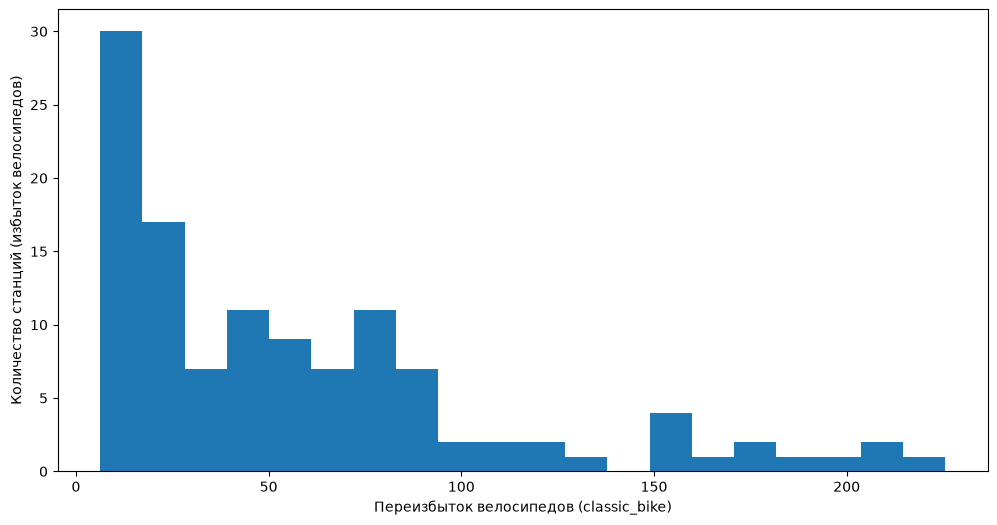

In [32]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    classic_bike[classic_bike['surplus'] > 5]['surplus'],
    bins=20
)

plt.xlabel('Переизбыток велосипедов (classic_bike)')
plt.ylabel('Количество станций (избыток велосипедов)')
plt.show()

- вывожу гистограмму выбрав дефицит велосипедов более 5

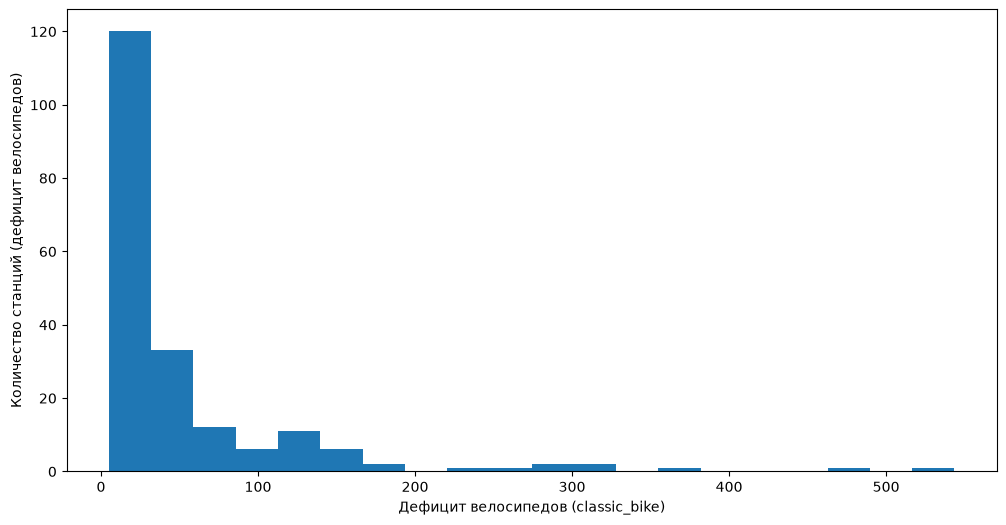

In [33]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    classic_bike[classic_bike['deficit'] > 5]['deficit'],
    bins=20
)

plt.xlabel('Дефицит велосипедов (classic_bike)')
plt.ylabel('Количество станций (дефицит велосипедов)')
plt.show()

### Сразу веведу docked_bike

In [33]:
docked_bike = result_type_bike[result_type_bike['rideable_type'] == 'docked_bike']
docked_bike

,rideable_type,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit
897,docked_bike,30200,9th St & Pennsylvania Ave NW,5815.0,576,10.095486,10.095486,0.000000
898,docked_bike,30201,9th & G St NW,1186.0,577,2.055459,2.055459,0.000000
899,docked_bike,31000,Eads St & 15th St S,-1398.0,1499,-0.932622,0.000000,0.932622
900,docked_bike,31001,18th St & S Eads St,-772.0,445,-1.734831,0.000000,1.734831
901,docked_bike,31002,Crystal Dr & 20th St S,-864.0,1548,-0.558140,0.000000,0.558140
...,...,...,...,...,...,...,...,...
1719,docked_bike,32609,W Columbia St & N Washington St,-152.0,1119,-0.135836,0.000000,0.135836
1720,docked_bike,32900,Motivate BX Tech office,12.0,50,0.240000,0.240000,0.000000
1721,docked_bike,32901,6035 Warehouse,32.0,347,0.092219,0.092219,0.000000
1722,docked_bike,32902,Motivate Tech Office,-1.0,3,-0.333333,0.000000,0.333333


- вывожу гистограмму выбрав профицит велосипедов более 5

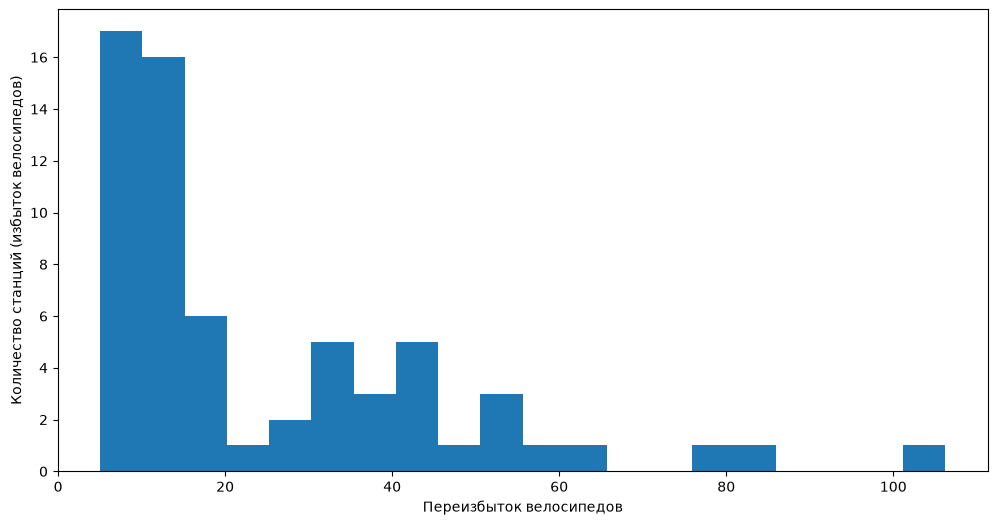

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    docked_bike[docked_bike['surplus'] > 5]['surplus'],
    bins=20
)

plt.xlabel('Переизбыток велосипедов')
plt.ylabel('Количество станций (избыток велосипедов)')
plt.show()

- вывожу гистограмму выбрав дефицит велосипедов более 5 

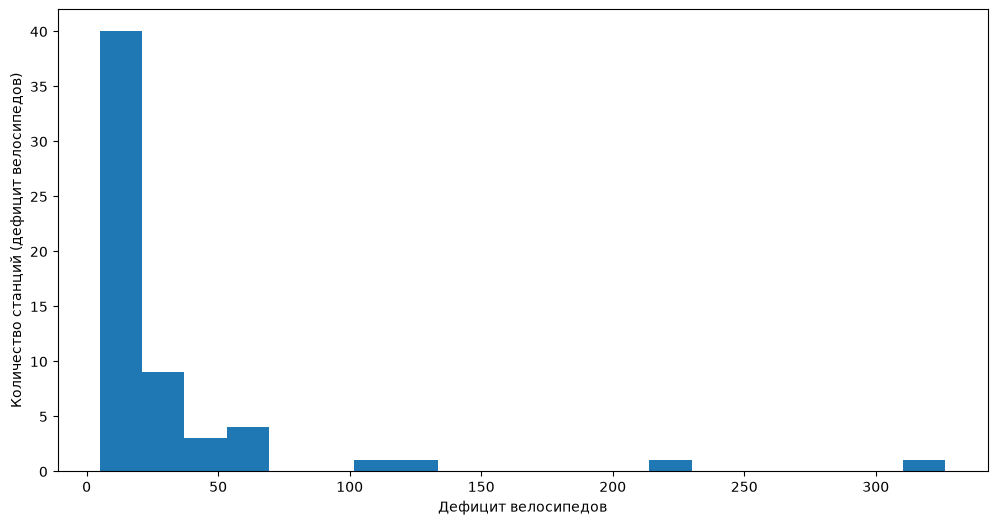

In [35]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    docked_bike[docked_bike['deficit'] > 5]['deficit'],
    bins=20
)

plt.xlabel('Дефицит велосипедов')
plt.ylabel('Количество станций (дефицит велосипедов)')
plt.show()

### Сразу веведу electric_bike

In [36]:
electric_bike = result_type_bike[result_type_bike['rideable_type'] == 'electric_bike']
electric_bike

,rideable_type,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit
1724,electric_bike,30200,9th St & Pennsylvania Ave NW,47358.0,576,82.218750,82.218750,0.000000
1725,electric_bike,30201,9th & G St NW,16948.0,577,29.372617,29.372617,0.000000
1726,electric_bike,31000,Eads St & 15th St S,-92.0,1499,-0.061374,0.000000,0.061374
1727,electric_bike,31001,18th St & S Eads St,-25.0,445,-0.056180,0.000000,0.056180
1728,electric_bike,31002,Crystal Dr & 20th St S,164.0,1548,0.105943,0.105943,0.000000
...,...,...,...,...,...,...,...,...
2614,electric_bike,32607,S Maple Ave & S Washington St,-301.0,1169,-0.257485,0.000000,0.257485
2615,electric_bike,32608,Falls Church City Hall / Park Ave & Little Fal...,-75.0,943,-0.079533,0.000000,0.079533
2616,electric_bike,32609,W Columbia St & N Washington St,-125.0,1119,-0.111707,0.000000,0.111707
2617,electric_bike,32901,6035 Warehouse,-69.0,347,-0.198847,0.000000,0.198847


- вывожу гистограмму выбрав профицит велосипедов более 5

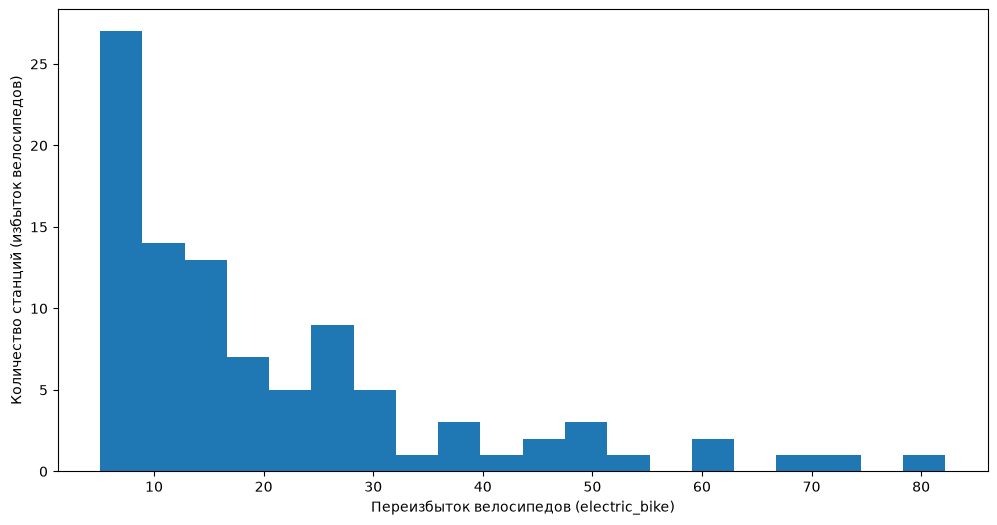

In [37]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    electric_bike[electric_bike['surplus'] > 5]['surplus'],
    bins=20
)

plt.xlabel('Переизбыток велосипедов (electric_bike)')
plt.ylabel('Количество станций (избыток велосипедов)')
plt.show()

- вывожу гистограмму выбрав дефицит велосипедов более 5

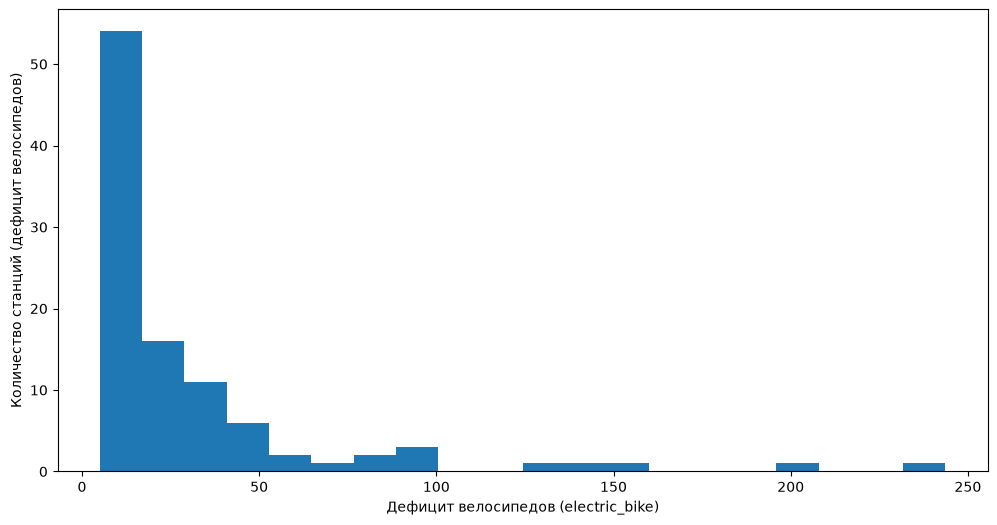

In [38]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    electric_bike[electric_bike['deficit'] > 5]['deficit'],
    bins=20
)

plt.xlabel('Дефицит велосипедов (electric_bike)')
plt.ylabel('Количество станций (дефицит велосипедов)')
plt.show()

### Осталось вывести поведение пользователей (member & casual)

- делаю группировку по столбцам member_casual, start_station_id, start_station_name и считаю сумму по столбцу change

In [35]:
result_member_casual = daily_rent_detail.groupby(
    ['member_casual', 'start_station_id', 'start_station_name']
)['change'].sum().reset_index()
result_member_casual

,member_casual,start_station_id,start_station_name,change
0,casual,30200,9th St & Pennsylvania Ave NW,86742.0
1,casual,30201,9th & G St NW,21496.0
2,casual,31000,Eads St & 15th St S,-3159.0
3,casual,31001,18th St & S Eads St,-534.0
4,casual,31002,Crystal Dr & 20th St S,-2394.0
...,...,...,...,...
1805,member,32609,W Columbia St & N Washington St,-849.0
1806,member,32900,Motivate BX Tech office,12.0
1807,member,32901,6035 Warehouse,-33.0
1808,member,32902,Motivate Tech Office,-1.0


- добавляю столбец station_work_day - то сколько дней работает станция

In [36]:
result_member_casual['station_work_day'] = result_member_casual['start_station_name'].map(station_work_day)

- добавляю еще один столбец imbalance_ratio - столбец показывает дефицит и профицит велосипедов

In [37]:
result_member_casual["imbalance_ratio"] = result_member_casual['change'] / result_member_casual['station_work_day']
result_member_casual

,member_casual,start_station_id,start_station_name,change,station_work_day,imbalance_ratio
0,casual,30200,9th St & Pennsylvania Ave NW,86742.0,576,150.593750
1,casual,30201,9th & G St NW,21496.0,577,37.254766
2,casual,31000,Eads St & 15th St S,-3159.0,1499,-2.107405
3,casual,31001,18th St & S Eads St,-534.0,445,-1.200000
4,casual,31002,Crystal Dr & 20th St S,-2394.0,1548,-1.546512
...,...,...,...,...,...,...
1805,member,32609,W Columbia St & N Washington St,-849.0,1119,-0.758713
1806,member,32900,Motivate BX Tech office,12.0,50,0.240000
1807,member,32901,6035 Warehouse,-33.0,347,-0.095101
1808,member,32902,Motivate Tech Office,-1.0,3,-0.333333


- также преобразовываю столбец imbalance_ratio в два новых столбца, где данные не будут отрицательными

In [38]:
result_member_casual["surplus"] = result_member_casual["imbalance_ratio"].clip(lower=0)
result_member_casual["deficit"] = (-result_member_casual["imbalance_ratio"]).clip(lower=0)

- вывожу результат

In [39]:
result_member_casual

,member_casual,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit
0,casual,30200,9th St & Pennsylvania Ave NW,86742.0,576,150.593750,150.593750,0.000000
1,casual,30201,9th & G St NW,21496.0,577,37.254766,37.254766,0.000000
2,casual,31000,Eads St & 15th St S,-3159.0,1499,-2.107405,0.000000,2.107405
3,casual,31001,18th St & S Eads St,-534.0,445,-1.200000,0.000000,1.200000
4,casual,31002,Crystal Dr & 20th St S,-2394.0,1548,-1.546512,0.000000,1.546512
...,...,...,...,...,...,...,...,...
1805,member,32609,W Columbia St & N Washington St,-849.0,1119,-0.758713,0.000000,0.758713
1806,member,32900,Motivate BX Tech office,12.0,50,0.240000,0.240000,0.000000
1807,member,32901,6035 Warehouse,-33.0,347,-0.095101,0.000000,0.095101
1808,member,32902,Motivate Tech Office,-1.0,3,-0.333333,0.000000,0.333333


- выбираю пользователей casual, для того что бы посмотреть дефицит и профицит велосипедов

In [40]:
casual_user = result_member_casual[result_member_casual['member_casual'] == 'casual']
casual_user

,member_casual,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit
0,casual,30200,9th St & Pennsylvania Ave NW,86742.0,576,150.593750,150.593750,0.000000
1,casual,30201,9th & G St NW,21496.0,577,37.254766,37.254766,0.000000
2,casual,31000,Eads St & 15th St S,-3159.0,1499,-2.107405,0.000000,2.107405
3,casual,31001,18th St & S Eads St,-534.0,445,-1.200000,0.000000,1.200000
4,casual,31002,Crystal Dr & 20th St S,-2394.0,1548,-1.546512,0.000000,1.546512
...,...,...,...,...,...,...,...,...
897,casual,32607,S Maple Ave & S Washington St,-673.0,1169,-0.575706,0.000000,0.575706
898,casual,32608,Falls Church City Hall / Park Ave & Little Fal...,-415.0,943,-0.440085,0.000000,0.440085
899,casual,32609,W Columbia St & N Washington St,-503.0,1119,-0.449508,0.000000,0.449508
900,casual,32901,6035 Warehouse,-66.0,347,-0.190202,0.000000,0.190202


- вывожу гистограмму выбрав профицит велосипедов более 5

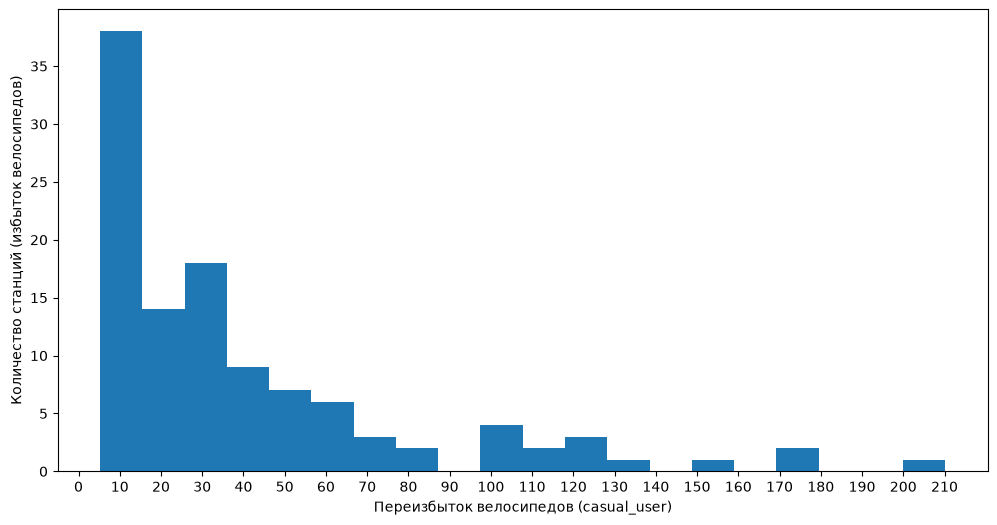

In [45]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    casual_user[casual_user['surplus'] > 5]['surplus'],
    bins=20
)

plt.xlabel('Переизбыток велосипедов (casual_user)')
plt.ylabel('Количество станций (избыток велосипедов)')

plt.xticks(np.arange(0, 220, 10))
plt.show()

- вывожу гистограмму выбрав дефицит велосипедов более 5

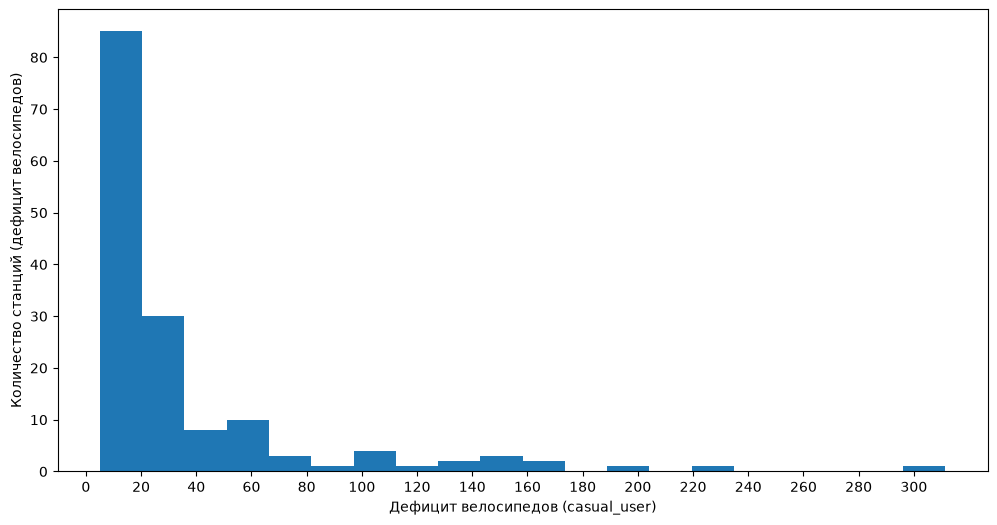

In [41]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    casual_user[casual_user['deficit'] > 5]['deficit'],
    bins=20
)

plt.xlabel('Дефицит велосипедов (casual_user)')
plt.ylabel('Количество станций (дефицит велосипедов)')

plt.xticks(np.arange(0, 320, 20))
plt.show()

- выбираю пользователей member, для того что бы посмотреть дефицит и профицит велосипедов

In [43]:
member_user = result_member_casual[result_member_casual['member_casual'] == 'member']
member_user

,member_casual,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit
902,member,30200,9th St & Pennsylvania Ave NW,87745.0,576,152.335069,152.335069,0.000000
903,member,30201,9th & G St NW,32499.0,577,56.324090,56.324090,0.000000
904,member,31000,Eads St & 15th St S,-2320.0,1499,-1.547698,0.000000,1.547698
905,member,31001,18th St & S Eads St,-513.0,445,-1.152809,0.000000,1.152809
906,member,31002,Crystal Dr & 20th St S,-2967.0,1548,-1.916667,0.000000,1.916667
...,...,...,...,...,...,...,...,...
1805,member,32609,W Columbia St & N Washington St,-849.0,1119,-0.758713,0.000000,0.758713
1806,member,32900,Motivate BX Tech office,12.0,50,0.240000,0.240000,0.000000
1807,member,32901,6035 Warehouse,-33.0,347,-0.095101,0.000000,0.095101
1808,member,32902,Motivate Tech Office,-1.0,3,-0.333333,0.000000,0.333333


- вывожу гистограмму выбрав профицит велосипедов более 5

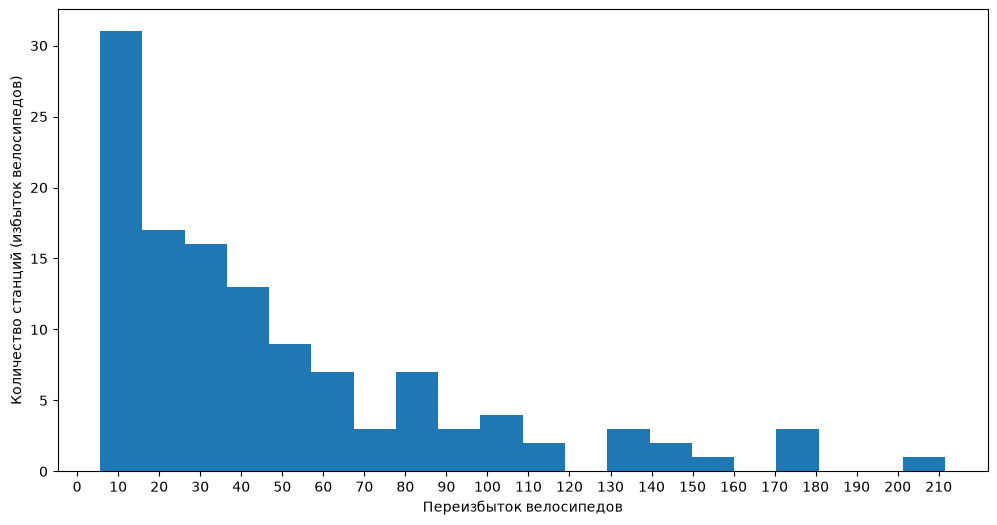

In [44]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    member_user[member_user['surplus'] > 5]['surplus'],
    bins=20
)

plt.xlabel('Переизбыток велосипедов')
plt.ylabel('Количество станций (избыток велосипедов)')

plt.xticks(np.arange(0, 220, 10))
plt.show()

- вывожу гистограмму выбрав дефицит велосипедов более 5

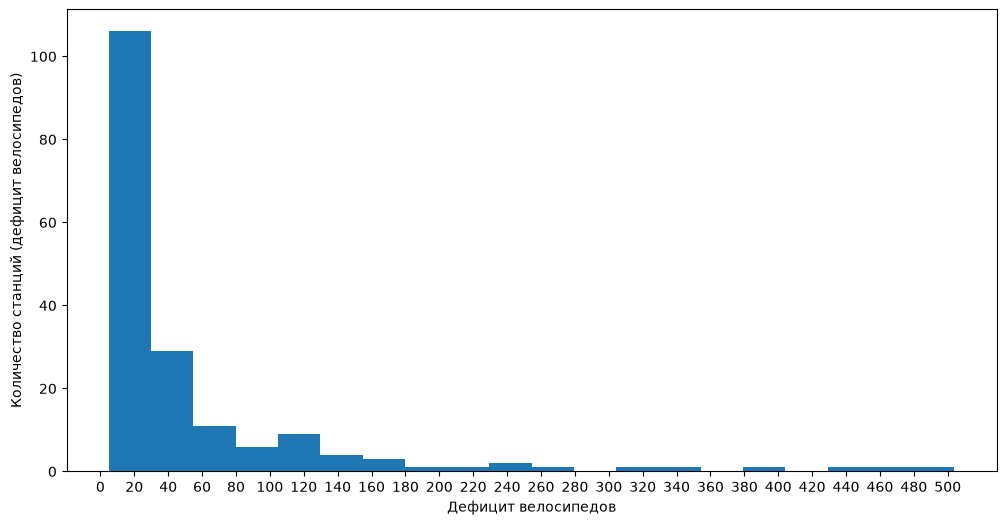

In [45]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    member_user[member_user['deficit'] > 5]['deficit'],
    bins=20
)

plt.xlabel('Дефицит велосипедов')
plt.ylabel('Количество станций (дефицит велосипедов)')

plt.xticks(np.arange(0, 520, 20))
plt.show()

**Промежуточный вывод по типам байков**
- Наблюдается тенденция что переизбытка велосипедов больше чем дефицит в независимости от типа велосипеда

**Промежуточный вывод по типам пользователей**
- Наблюдается тенденция что переизбытка велосипедов больше чем дефицит в независимоти от типа пользователей
- Больше избытка велосипедов создают пользователи member

## Вывод
- 

## Сборка данных для dashboard_supervisor

In [50]:
dashboard_supervisor = daily_rent_detail.groupby(
    ['date', 'rideable_type','member_casual' ,'start_station_id', 'start_station_name']
)['change'].sum().reset_index()
dashboard_supervisor

,date,rideable_type,member_casual,start_station_id,start_station_name,change
0,2020-05-01,docked_bike,casual,31000,Eads St & 15th St S,-3.0
1,2020-05-01,docked_bike,casual,31002,Crystal Dr & 20th St S,-4.0
2,2020-05-01,docked_bike,casual,31003,Crystal Dr & 15th St S,6.0
3,2020-05-01,docked_bike,casual,31005,Pentagon City Metro / 12th St & S Hayes St,3.0
4,2020-05-01,docked_bike,casual,31006,Army Navy Dr & S Joyce St,30.0
...,...,...,...,...,...,...
2304792,2024-08-31,electric_bike,member,32426,Greenbelt Station Parkway,-1.0
2304793,2024-08-31,electric_bike,member,32601,Eden Center,-2.0
2304794,2024-08-31,electric_bike,member,32602,N Oak St & W Broad St,3.0
2304795,2024-08-31,electric_bike,member,32604,E Fairfax St & S Washington St,4.0


In [51]:
dashboard_supervisor['station_work_day'] = dashboard_supervisor['start_station_name'].map(station_work_day)

In [52]:
dashboard_supervisor["imbalance_ratio"] = dashboard_supervisor['change'] / dashboard_supervisor['station_work_day']
dashboard_supervisor

,date,rideable_type,member_casual,start_station_id,start_station_name,change,station_work_day,imbalance_ratio
0,2020-05-01,docked_bike,casual,31000,Eads St & 15th St S,-3.0,1499,-0.002001
1,2020-05-01,docked_bike,casual,31002,Crystal Dr & 20th St S,-4.0,1548,-0.002584
2,2020-05-01,docked_bike,casual,31003,Crystal Dr & 15th St S,6.0,1560,0.003846
3,2020-05-01,docked_bike,casual,31005,Pentagon City Metro / 12th St & S Hayes St,3.0,1562,0.001921
4,2020-05-01,docked_bike,casual,31006,Army Navy Dr & S Joyce St,30.0,936,0.032051
...,...,...,...,...,...,...,...,...
2304792,2024-08-31,electric_bike,member,32426,Greenbelt Station Parkway,-1.0,631,-0.001585
2304793,2024-08-31,electric_bike,member,32601,Eden Center,-2.0,589,-0.003396
2304794,2024-08-31,electric_bike,member,32602,N Oak St & W Broad St,3.0,1028,0.002918
2304795,2024-08-31,electric_bike,member,32604,E Fairfax St & S Washington St,4.0,844,0.004739


In [53]:
dashboard_supervisor["surplus"] = dashboard_supervisor["imbalance_ratio"].clip(lower=0)
dashboard_supervisor["deficit"] = (-dashboard_supervisor["imbalance_ratio"]).clip(lower=0)

In [54]:
dashboard_supervisor['surplus'] = dashboard_supervisor['surplus'].round()
dashboard_supervisor['deficit'] = dashboard_supervisor['deficit'].round()

In [55]:
dashboard_supervisor['month'] =  dashboard_supervisor['date'].dt.month

In [60]:
dashboard_supervisor['month_name'] =  dashboard_supervisor['date'].dt.month_name()

In [57]:
dashboard_supervisor['day_of_week'] =  dashboard_supervisor['date'].dt.day_of_week

In [58]:
dashboard_supervisor['day_name'] = dashboard_supervisor['date'].dt.day_name()

In [61]:
dashboard_supervisor

,date,rideable_type,member_casual,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit,month,month_name,day_of_week,day_name
0,2020-05-01,docked_bike,casual,31000,Eads St & 15th St S,-3.0,1499,-0.002001,0.0,0.0,5,May,4,Friday
1,2020-05-01,docked_bike,casual,31002,Crystal Dr & 20th St S,-4.0,1548,-0.002584,0.0,0.0,5,May,4,Friday
2,2020-05-01,docked_bike,casual,31003,Crystal Dr & 15th St S,6.0,1560,0.003846,0.0,0.0,5,May,4,Friday
3,2020-05-01,docked_bike,casual,31005,Pentagon City Metro / 12th St & S Hayes St,3.0,1562,0.001921,0.0,0.0,5,May,4,Friday
4,2020-05-01,docked_bike,casual,31006,Army Navy Dr & S Joyce St,30.0,936,0.032051,0.0,0.0,5,May,4,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2304792,2024-08-31,electric_bike,member,32426,Greenbelt Station Parkway,-1.0,631,-0.001585,0.0,0.0,8,August,5,Saturday
2304793,2024-08-31,electric_bike,member,32601,Eden Center,-2.0,589,-0.003396,0.0,0.0,8,August,5,Saturday
2304794,2024-08-31,electric_bike,member,32602,N Oak St & W Broad St,3.0,1028,0.002918,0.0,0.0,8,August,5,Saturday
2304795,2024-08-31,electric_bike,member,32604,E Fairfax St & S Washington St,4.0,844,0.004739,0.0,0.0,8,August,5,Saturday


In [62]:
dashboard_supervisor.info()

<class 'pandas.DataFrame'>
RangeIndex: 2304797 entries, 0 to 2304796
Data columns (total 14 columns):
 #   Column              Dtype        
---  ------              -----        
 0   date                datetime64[s]
 1   rideable_type       str          
 2   member_casual       str          
 3   start_station_id    int32        
 4   start_station_name  str          
 5   change              float64      
 6   station_work_day    int64        
 7   imbalance_ratio     float64      
 8   surplus             float64      
 9   deficit             float64      
 10  month               int32        
 11  month_name          str          
 12  day_of_week         int32        
 13  day_name            str          
dtypes: datetime64[s](1), float64(4), int32(3), int64(1), str(5)
memory usage: 342.7 MB


In [63]:
dashboard_supervisor = dashboard_supervisor.astype(
    {
        'rideable_type': 'object',
        'member_casual': 'object',
        'date': 'datetime64[us]',
        'start_station_name': 'object',
        'change': 'float32',
        'station_work_day': 'int32',
        'imbalance_ratio': 'float32',
        'surplus': 'int32',
        'deficit': 'int32',
        'month_name': 'object',
        'day_name': 'object'
    }
)

In [64]:
dashboard_supervisor.info()

<class 'pandas.DataFrame'>
RangeIndex: 2304797 entries, 0 to 2304796
Data columns (total 14 columns):
 #   Column              Dtype         
---  ------              -----         
 0   date                datetime64[us]
 1   rideable_type       object        
 2   member_casual       object        
 3   start_station_id    int32         
 4   start_station_name  object        
 5   change              float32       
 6   station_work_day    int32         
 7   imbalance_ratio     float32       
 8   surplus             int32         
 9   deficit             int32         
 10  month               int32         
 11  month_name          object        
 12  day_of_week         int32         
 13  day_name            object        
dtypes: datetime64[us](1), float32(2), int32(6), object(5)
memory usage: 175.8+ MB


In [65]:
dashboard_supervisor

,date,rideable_type,member_casual,start_station_id,start_station_name,change,station_work_day,imbalance_ratio,surplus,deficit,month,month_name,day_of_week,day_name
0,2020-05-01,docked_bike,casual,31000,Eads St & 15th St S,-3.0,1499,-0.002001,0,0,5,May,4,Friday
1,2020-05-01,docked_bike,casual,31002,Crystal Dr & 20th St S,-4.0,1548,-0.002584,0,0,5,May,4,Friday
2,2020-05-01,docked_bike,casual,31003,Crystal Dr & 15th St S,6.0,1560,0.003846,0,0,5,May,4,Friday
3,2020-05-01,docked_bike,casual,31005,Pentagon City Metro / 12th St & S Hayes St,3.0,1562,0.001921,0,0,5,May,4,Friday
4,2020-05-01,docked_bike,casual,31006,Army Navy Dr & S Joyce St,30.0,936,0.032051,0,0,5,May,4,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2304792,2024-08-31,electric_bike,member,32426,Greenbelt Station Parkway,-1.0,631,-0.001585,0,0,8,August,5,Saturday
2304793,2024-08-31,electric_bike,member,32601,Eden Center,-2.0,589,-0.003396,0,0,8,August,5,Saturday
2304794,2024-08-31,electric_bike,member,32602,N Oak St & W Broad St,3.0,1028,0.002918,0,0,8,August,5,Saturday
2304795,2024-08-31,electric_bike,member,32604,E Fairfax St & S Washington St,4.0,844,0.004739,0,0,8,August,5,Saturday


In [66]:
dashboard_supervisor['surplus'].mean() , dashboard_supervisor['deficit'].mean()

(np.float64(0.0013628098266354912), np.float64(0.0024006452629016786))

In [67]:
dashboard_supervisor.describe()

,date,start_station_id,change,station_work_day,imbalance_ratio,surplus,deficit,month,day_of_week
count,2304797,2.304797e+06,2.304797e+06,2.304797e+06,2.304797e+06,2.304797e+06,2.304797e+06,2.304797e+06,2.304797e+06
mean,2022-09-22 00:24:40.250453,3.144974e+04,-3.286418e+00,1.353287e+03,-2.376892e-03,1.362810e-03,2.400645e-03,6.595467e+00,3.023231e+00
min,2020-05-01 00:00:00,3.020000e+04,-9.312000e+03,1.000000e+00,-7.431764e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
25%,2021-09-11 00:00:00,3.120700e+04,-8.000000e+00,1.286000e+03,-5.685408e-03,0.000000e+00,0.000000e+00,4.000000e+00,1.000000e+00
50%,2022-10-16 00:00:00,3.131500e+04,0.000000e+00,1.542000e+03,0.000000e+00,0.000000e+00,0.000000e+00,7.000000e+00,3.000000e+00
75%,2023-10-07 00:00:00,3.164400e+04,5.000000e+00,1.579000e+03,3.811944e-03,0.000000e+00,0.000000e+00,9.000000e+00,5.000000e+00
max,2024-08-31 00:00:00,3.320000e+04,1.794700e+04,1.584000e+03,1.142393e+01,1.100000e+01,7.000000e+00,1.200000e+01,6.000000e+00
std,NaN,3.584770e+02,9.753766e+01,3.531411e+02,7.564313e-02,4.085348e-02,5.271083e-02,3.123262e+00,1.991116e+00


In [78]:
dashboard_supervisor.to_csv('../../../dashboards/dashboard_supervisor_rebalace.csv', index=False)

In [68]:
table_for_parquet = pa.Table.from_pandas(dashboard_supervisor)

In [69]:
pq.write_table(table_for_parquet, '../../../dashboards/dashboard_supervisor_rebalace.parquet')

## Сборка данных для dashboard_service_analyst

In [73]:
daily_rent_detail

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,duration_in_minutes,date,pickup_counts,dropoff_counts,change,station_work_day
0,946D42AD89539210,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,Anacostia Library,31804,11th & H St NE,31614,38.865784,-76.978401,38.899982,-76.991386,casual,1499.883301,2020-05-30,3,1.0,-2.0,1045
1,CC46FAAB662B8613,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,10th & E St NW,31256,21st St & Constitution Ave NW,31261,38.895912,-77.026062,38.892460,-77.046570,member,24.483334,2020-05-09,4,4.0,0.0,1573
2,72F00B2FB833D6ED,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,12th & U St NW,31268,38.934265,-77.057976,38.916786,-77.028137,member,16.533333,2020-05-24,17,10.0,-7.0,667
3,4DFBE6AED989DF35,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,Connecticut Ave & Newark St NW / Cleveland Park,31305,14th & Belmont St NW,31119,38.934265,-77.057976,38.921074,-77.031883,casual,17.350000,2020-05-27,13,11.0,-2.0,667
4,1AAFE6B4331AB9DF,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,Georgia Ave & Morton St NW,31419,17th & K St NW,31213,38.932129,-77.023499,38.902760,-77.038628,casual,24.450001,2020-05-31,12,11.0,-1.0,1579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13920681,0B1E598A0BB5267A,classic_bike,2024-08-22 18:12:12.444,2024-08-22 18:59:58.532,Braddock Rd Metro North,31047,Braddock Rd Metro North,31047,38.814575,-77.052811,38.814575,-77.052811,casual,47.768135,2024-08-22,9,6.0,-3.0,893
13920682,F5F912CEC7167D79,classic_bike,2024-08-23 11:58:30.749,2024-08-23 12:00:33.749,10th & H St NE,31672,10th & H St NE,31672,38.899982,-76.992722,38.899982,-76.992722,casual,2.050000,2024-08-23,40,31.0,-9.0,1004
13920683,9E2EEBF255746B1E,electric_bike,2024-08-22 13:09:17.036,2024-08-22 13:35:13.814,Wisconsin Ave & Newark St NW,31302,Wisconsin Ave & Newark St NW,31302,38.934879,-77.072754,38.934879,-77.072754,member,25.946301,2024-08-22,34,37.0,3.0,1583
13920684,2CBC6A5EB1668ABB,electric_bike,2024-08-17 09:24:19.031,2024-08-17 09:41:27.044,14th & Belmont St NW,31119,Wisconsin Ave & Newark St NW,31302,38.920807,-77.031548,38.934879,-77.072754,casual,17.133551,2024-08-17,90,83.0,-7.0,1582


In [76]:
dashboard_service_analyst = daily_rent_detail.groupby(
    ['date', 'rideable_type','member_casual' ,'start_station_id', 'start_station_name']
)[['duration_in_minutes', 'change']].sum().reset_index()
dashboard_service_analyst

,date,rideable_type,member_casual,start_station_id,start_station_name,duration_in_minutes,change
0,2020-05-01,docked_bike,casual,31000,Eads St & 15th St S,52.116665,-3.0
1,2020-05-01,docked_bike,casual,31002,Crystal Dr & 20th St S,22.066668,-4.0
2,2020-05-01,docked_bike,casual,31003,Crystal Dr & 15th St S,244.133331,6.0
3,2020-05-01,docked_bike,casual,31005,Pentagon City Metro / 12th St & S Hayes St,88.216667,3.0
4,2020-05-01,docked_bike,casual,31006,Army Navy Dr & S Joyce St,192.050003,30.0
...,...,...,...,...,...,...,...
2304792,2024-08-31,electric_bike,member,32426,Greenbelt Station Parkway,61.425549,-1.0
2304793,2024-08-31,electric_bike,member,32601,Eden Center,14.699833,-2.0
2304794,2024-08-31,electric_bike,member,32602,N Oak St & W Broad St,4.418817,3.0
2304795,2024-08-31,electric_bike,member,32604,E Fairfax St & S Washington St,16.614317,4.0


- Дашборд для руководителя сервисного отдела
    - Вывести срез с профицитом велосипедов за каждый день (станции)
    - Вывести срез с дефицитом велосипедов за каждый день (станции)
    - Вывести график bar для отслеживания дефицита и профицита велосипедов на станции (за каждый день) 
    - Можно вывести KPI по которому можно будет примировать сотрудников занимающихся перевозкой велосипедов
    - Частота обновления - сначала по дням, а затем увеличивать в плоть до месяца (Оставлять только большие периоды минимум месяц)


    Что нужно добавить:
        - Дату (ее можно сразу добавить в срез и смотреть по дням)

- Дашбоард для аналитика сервисного отдела
    - Сколько превезли велосипедов - сколько нужно перевезти велосипедов (такие данные я не могу получить)
    - Вывести график аренды минут по дням (что бы видеть динамику аренды велосипедов)
    - Вывести столбчатую диаграмму количества аренды велосипедов за день (в дальнейшем увеличить период наблюдения)
    - Частота обновления - сначала по дням, а затем увеличивать в плоть до месяца (Приоритет к коротким периодам для отслеживания)

- Презинтацию делать отдельно для каждого из (руководитель и аналитика сервисного отдела)